# Cat or Dogs -- CNN with Transfer Learning(ResNet-50)


# 1. Introduction

## Dataset
The **train** folder has **25,000** images of dogs and cats; the label is in the file name (`cat.123.jpg`, `dog.45.jpg`).
The **test** folder has **12,500** images named by id (`1.jpg`, `2.jpg`, ...).
For each test image we predict the **probability that it is a dog** (1 = dog, 0 = cat).

## Method: transfer learning in two phases
1. **Feature extraction:** take ResNet-50 trained on ImageNet, **freeze** it, and train only a small new classifier on top.
2. **Fine-tuning (optional):** unfreeze the last block of ResNet-50 and train it a little more with a **very small learning rate**.

Why two phases? The new top layer starts random. If ResNet were trainable from the start, the large, random gradients from that layer would flow back and damage the pretrained features. Training the top first, then gently adjusting ResNet, is the safe order.

In [5]:
import os, zipfile, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from jupyter_client import channels
from matplotlib.lines import lineStyles
from tensorflow import keras
from tensorflow.keras import layers

from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.python.keras.utils.version_utils import training
from zmq import XPUB_MANUAL_LAST_VALUE

%matplotlib inline

print("TensorFlow version: ", tf.__version__)
print("GPUs found: ", tf.config.list_physical_devices("GPU"))

TensorFlow version:  2.21.0
GPUs found:  []


In [6]:
SEED = 2018
VAL_size = 0.2  #20% of the sample for validation
BATCH_SIZE = 32
IMG_SIZE = 224  # ResNet-50 was trained on 224x224 images
SAMPLE_SIZE = 20000
EPOCHS_HEAD = 5 # phase 1: train only the new top layer
EPOCHS_FINE = 3 # phase 2: fine-tune the last ResNet block
DATA_DIR = r"C:\Users\asus\Desktop\Cnn"  # folder that holds train.zip and test.zip
WORK_DIR = r"C:\Users\asus\Desktop\Cnn"  # folder where the images are extracted (train/ and test/)

 # 3. Read the data

The competition provides zip files. We extract them once into the working folder.
🔧 Updated: the function skips extraction if it already happened (useful when you re-run cells), and also works if the dataset is already unzipped.

In [8]:
def extract_if_needed(zip_name , folder_name):
    target = os.path.join(WORK_DIR, folder_name)
    if os.path.isdir(target):
        print(f"{target} already exists, skipping extraction")
        return target
    zip_path = os.path.join(DATA_DIR, zip_name)
    if os.path.exists(zip_path):
        print(f"Extracting {zip_path}....")
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(WORK_DIR)
        return target
    already_unzipped = os.path.join(DATA_DIR, folder_name)
    if os.path.isdir(already_unzipped):
        return already_unzipped
    raise FileNotFoundError(f"Could not find {zip_name} or {folder_name}/ in {DATA_DIR}.")


TRAIN_FOLDER = extract_if_needed("train.zip", "train")
TEST_FOLDER = extract_if_needed("test.zip", "test")

C:\Users\asus\Desktop\Cnn\train already exists, skipping extraction
C:\Users\asus\Desktop\Cnn\test already exists, skipping extraction


## File lists and labels

We keep **file paths** and **labels**, not the images themselves. Images are loaded later, batch by batch.

🔧 Updated: we shuffle with a fixed seed before taking the sample. `os.listdir` returns files in an arbitrary order, so "the first 20,000" may not be a fair sample, and it can differ between machines.
Labels are now a single number (0 = cat, 1 = dog) instead of one-hot `[1,0]` / `[0,1]`, which matches the single sigmoid output we use later.

In [9]:
def label_from_name(fname):
    # 'cat.123.jpg' -> 0, 'dog.45.jpg' -> 1
    return 1 if fname.split(".")[0] == "dog" else 0

all_train_files = sorted(os.listdir(TRAIN_FOLDER))
random.shuffle(all_train_files) #seeded above, so repeatable

train_files = all_train_files[:SAMPLE_SIZE] if SAMPLE_SIZE else all_train_files

train_paths = np.array([os.path.join( TRAIN_FOLDER,f ) for f in train_files])
train_labels = np.array([label_from_name(f) for f in train_files])

# Sort test files by their numeric id so the submission is in order
test_files = sorted(os.listdir(TEST_FOLDER), key=lambda f: int(f.split(".")[0]))
test_paths = np.array([os.path.join(TEST_FOLDER, f) for f in test_files])

test_ids = [int(f.split(".")[0]) for f in test_files]

print(f"Training Sample : {len(train_paths)} images | Test set: {len(test_paths)} images")

Training Sample : 20000 images | Test set: 12500 images


# 4. Data exploration

## Class distribution
🔧 Updated: `sns.countplot(x=...)`; newer seaborn needs the keyword.

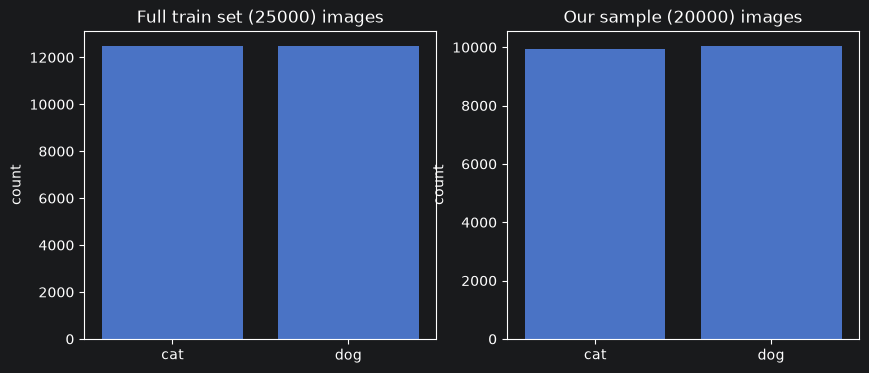

In [10]:
full_labels = ["dog" if label_from_name(f) else "cat" for f in all_train_files]
sample_labels = ["dog" if l else "cat" for l in train_labels]

fig , ax = plt.subplots(1,2 , figsize=(10, 4))
sns.countplot(x=full_labels, ax=ax[0], order=["cat", "dog"])
ax[0].set_title(f"Full train set ({len(full_labels)}) images")
sns.countplot(x=sample_labels, ax=ax[1], order=["cat", "dog"])
ax[1].set_title(f"Our sample ({len(sample_labels)}) images")
plt.show()

## Train / validation split

We split **before** loading any images.
🔧 Updated: `stratify=` keeps the same cat/dog ratio in both sets, and the validation set is 20% instead of 50%.

In [12]:
X_train_paths, X_val_paths, y_train , y_val = train_test_split(train_paths, train_labels, test_size=VAL_size, random_state=SEED, stratify=train_labels)

print("Train: ", len(X_train_paths),"| Validation : ", len(X_val_paths))

Train:  16000 | Validation :  4000


## Loading images with `tf.data`

🔧 Updated: this replaces the original `process_data` function, which put every image into one huge list in memory.
A `tf.data` pipeline reads, resizes and preprocesses images **in batches while the GPU is training**, so memory stays small and the GPU is not left waiting.

Two important details:
- `decode_jpeg` gives images in **RGB** order. `cv2.imread` (used in the original) gives **BGR**, which is why the original's plotted cats looked blue.
- `preprocess_input` converts images to the exact format ResNet-50 saw during its ImageNet training. A pretrained model only works well on inputs prepared the same way it was trained.

In [13]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path):
    img = tf.io.read_file(path)
    img = tf.io.decode_jpeg(img, channels=3)    # RGB, values 0....255
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))    # float32
    return img

def load_and_preprocess(path):
    return preprocess_input(load_image(path))   # ResNet-50's own preprocessing

def make_dataset(paths, labels=None, shuffle=False):
    if labels is None:
        ds = tf.data.Dataset.from_tensor_slices(paths)
        ds = ds.map(load_and_preprocess, num_parallel_calls=AUTOTUNE)
    else :
        ds = tf.data.Dataset.from_tensor_slices((paths,labels.astype("float32")))
        if shuffle:
            ds = ds.shuffle(len(paths), seed=SEED)
        ds = ds.map(lambda p , y: (load_and_preprocess(p),y),num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(X_train_paths, y_train, shuffle=True)
val_ds = make_dataset(X_val_paths, y_val)   # Not shuffled, so predictions line up with y_val
test_ds = make_dataset(test_paths)

## Image samples

For display we load the raw images (without `preprocess_input`, which changes the colours and would look strange).

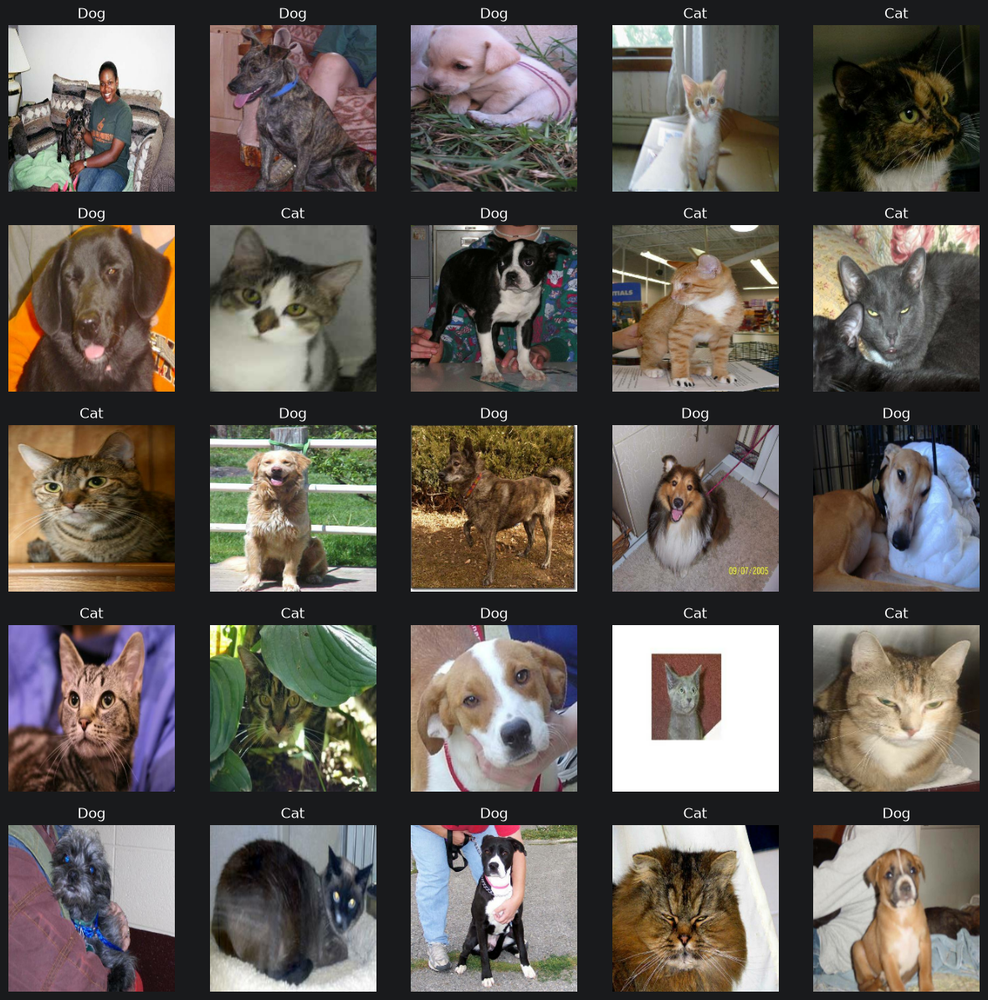

In [15]:
def show_images(paths, titles):
    fig, ax = plt.subplots(5,5 , figsize=(15,15))
    for i, (path, title) in enumerate(zip(paths[:25],titles[:25])):
        img = load_image(path).numpy().astype("uint8")
        ax[i // 5, i%5].imshow(img)
        ax[i // 5, i%5].set_title(title)
        ax[i // 5, i%5].axis("off")
    plt.show()

show_images(X_train_paths, ["Dog" if l else "Cat" for l in y_train])

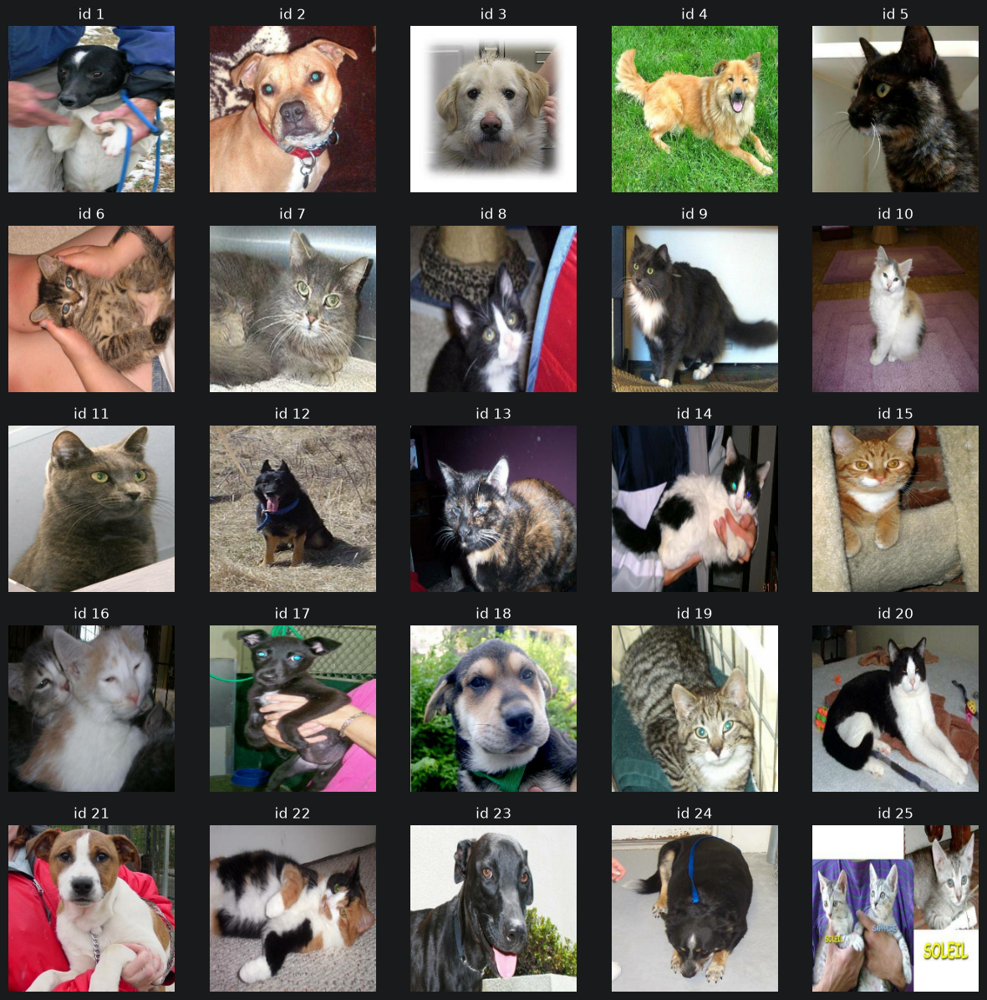

In [16]:
show_images(test_paths, [f"id {i}" for i in test_ids])

# 5. Model

## Data augmentation
🔧 Updated (new): random flips, small rotations and zooms create slightly different versions of each training image every epoch. The model sees more variety and memorises less.
These layers only act during training; during `evaluate` and `predict` they do nothing.

In [17]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="augmentation")

## Build the model

🔧 Updated:
- `weights="imagenet"` downloads the pretrained weights automatically (no `.h5` dataset needed).
- `base_model.trainable = False` **freezes** ResNet-50. The original set it to `True`, which contradicted its own comment.
- `base_model(x, training=False)` keeps ResNet's **BatchNormalization** layers in inference mode, even later when we fine-tune. Otherwise they would update their statistics from our small batches and hurt accuracy.
- **Functional API** (`keras.Input` → layers → `keras.Model`) instead of `Sequential`, because we need to pass `training=False`.
- `GlobalAveragePooling2D` turns ResNet's 7×7×2048 feature map into 2048 numbers (the original used max pooling; average pooling is the usual choice).
- `Dropout(0.2)` randomly switches off 20% of features during training, which reduces overfitting.
- **One output with sigmoid**: it directly gives P(dog), which is what the competition asks for.

In [18]:
base_model = ResNet50(
    include_top=False,  # drop ImageNet's 1000-class layer
    weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = False    # phase 1: freeze ResNet-50

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = data_augmentation(inputs)
x = base_model(x , training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(1, activation='sigmoid')(x)
model = keras.Model(inputs, outputs, name="cats_vs_dogs_resnet50")

model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 14s 0us/step


Model: "cats_vs_dogs_resnet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         2,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,589,761 (89.99 MB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

Look at the summary: **Trainable params** should be only about 2,049 (2048 weights + 1 bias in the last layer), while about 23.5 million are non-trainable.
That small number is the whole point of transfer learning: we reuse what ResNet already knows.

## Compile
🔧 Updated: **Adam** instead of SGD (adapts its step size, usually faster to converge), and **binary cross-entropy** because we have one sigmoid output.
The original's text called SGD a "sigmoid optimizer"; that is a mistake. SGD means *stochastic gradient descent*.

In [19]:
model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
              loss="binary_crossentropy",
              metrics=["accuracy"])

## Phase 1: train the new top layer

🔧 Updated: `EarlyStopping` watches the validation loss, stops when it stops improving for 2 epochs, and restores the best weights. This replaces guessing a fixed number of epochs.

In [20]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss",  patience=2,restore_best_weights=True)


history_head = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD, callbacks=[early_stop])

Epoch 1/5


C:\Users\asus\Desktop\Cnn\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


500/500 ━━━━━━━━━━━━━━━━━━━━ 1293s 3s/step - accuracy: 0.9639 - loss: 0.0982 - val_accuracy: 0.9887 - val_loss: 0.0340
Epoch 2/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 1176s 2s/step - accuracy: 0.9803 - loss: 0.0531 - val_accuracy: 0.9862 - val_loss: 0.0365
Epoch 3/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 19094s 38s/step - accuracy: 0.9819 - loss: 0.0479 - val_accuracy: 0.9910 - val_loss: 0.0274
Epoch 4/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 1651s 3s/step - accuracy: 0.9833 - loss: 0.0445 - val_accuracy: 0.9908 - val_loss: 0.0287
Epoch 5/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 1137s 2s/step - accuracy: 0.9828 - loss: 0.0444 - val_accuracy: 0.9915 - val_loss: 0.0271


## Phase 2: fine-tune the last ResNet block (optional)

Now that the top layer is trained, we unfreeze only the **last block** of ResNet-50 (layers named `conv5_...`) and train with a learning rate **100 times smaller**.
- Only the last block: early layers detect general things (edges, textures) that are useful for any image; later layers are more specific, so they benefit most from adapting to cats and dogs.
- Tiny learning rate: we want small adjustments, not to overwrite what was learned.
- BatchNormalization layers stay frozen (explained above).
- **You must `compile` again** after changing `trainable`, or the change has no effect.

In [22]:
base_model.trainable = True
for layer in base_model.layers:
    if not layer.name.startswith("conv5_") and not  isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-5),
              loss="binary_crossentropy",
              metrics=["accuracy"])

trainable_count = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
print(f"Trainable parameters now: {trainable_count:,}")

history_fine = model.fit(train_ds,
                         validation_data=val_ds,
                         epochs=1,
                         callbacks=[early_stop])

Trainable parameters now: 14,955,521
500/500 ━━━━━━━━━━━━━━━━━━━━ 1496s 3s/step - accuracy: 0.9858 - loss: 0.0375 - val_accuracy: 0.9915 - val_loss: 0.0266


## Training and validation accuracy and loss
🔧 Updated: history keys are now `accuracy` / `val_accuracy` (the original used `acc` / `val_acc`). The dashed line marks where fine-tuning started.

**How to read these curves:**
- Training and validation both improving → good.
- Training keeps improving but validation gets worse → **overfitting** (the model is memorising).
- Validation accuracy higher than training at the start is normal here: dropout and augmentation are active only during training.

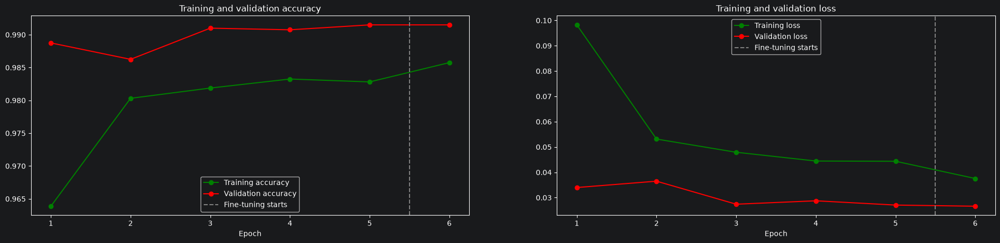

In [23]:
def plot_history(histories):
    hist = {}
    for h in histories:
        for k , v in h.history.items():
            hist.setdefault(k,[]).extend(v)
    epochs = range(1, len(hist["loss"]) + 1)
    fine_start = len(histories[0].history["loss"]) + 0.5

    fig , ax = plt.subplots(1,2, figsize=(24,5))
    for a, metric in zip(ax, ["accuracy","loss"]):
        a.plot(epochs, hist[metric],"g-o",
               label=f"Training {metric}")
        a.plot(epochs, hist[f"val_{metric}"],"r-o",
               label=f"Validation {metric}")
        if len(histories) > 1:
            a.axvline(fine_start , color="gray",
                      linestyle="--",label="Fine-tuning starts")
        a.set_xlabel("Epoch")
        a.set_title(f"Training and validation {metric}")
        a.legend()
    plt.show()

plot_history([history_head, history_fine])

In [24]:
val_loss, val_acc = model.evaluate(val_ds, verbose=0)
print(f"Validation loss: {val_loss: .4f}")
print(f"Validation accuracy: {val_acc: .4f}")

Validation loss:  0.0266
Validation accuracy:  0.9915


## Validation results per class
🔧 Updated: `predict_classes` was removed from Keras. We get probabilities with `predict` and call it a dog when P(dog) > 0.5.
We also add a **confusion matrix**, which shows *which* mistakes the model makes (cats called dogs, or dogs called cats).

125/125 ━━━━━━━━━━━━━━━━━━━━ 255s 2s/step
              precision    recall  f1-score   support

         cat       0.99      0.99      0.99      1989
         dog       0.99      0.99      0.99      2011

    accuracy                           0.99      4000
   macro avg       0.99      0.99      0.99      4000
weighted avg       0.99      0.99      0.99      4000



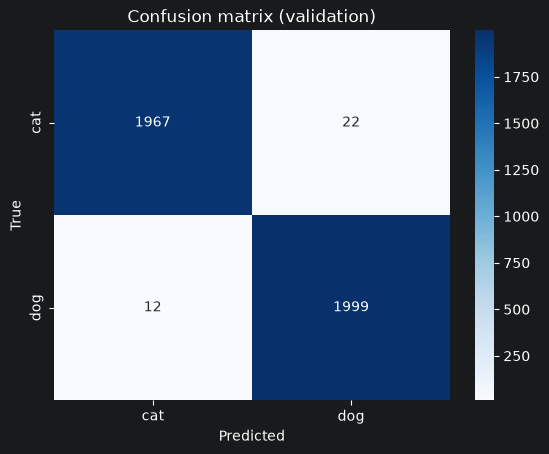

In [25]:
val_probs = model.predict(val_ds).ravel()
val_pred = (val_probs > 0.5).astype(int)

print(classification_report(y_val, val_pred, target_names=["cat", "dog"]))

cm = confusion_matrix(y_val, val_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["cat", "dog"], yticklabels=["cat", "dog"])
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion matrix (validation)")
plt.show()

## Look at the mistakes
🔧 New: one of the most useful habits in machine learning. Looking at the images the model got wrong tells you *why* it fails: blurry photos, several animals, a person holding the pet, or sometimes a **wrong label** in the dataset.

34 wrong out of 4000 validation images


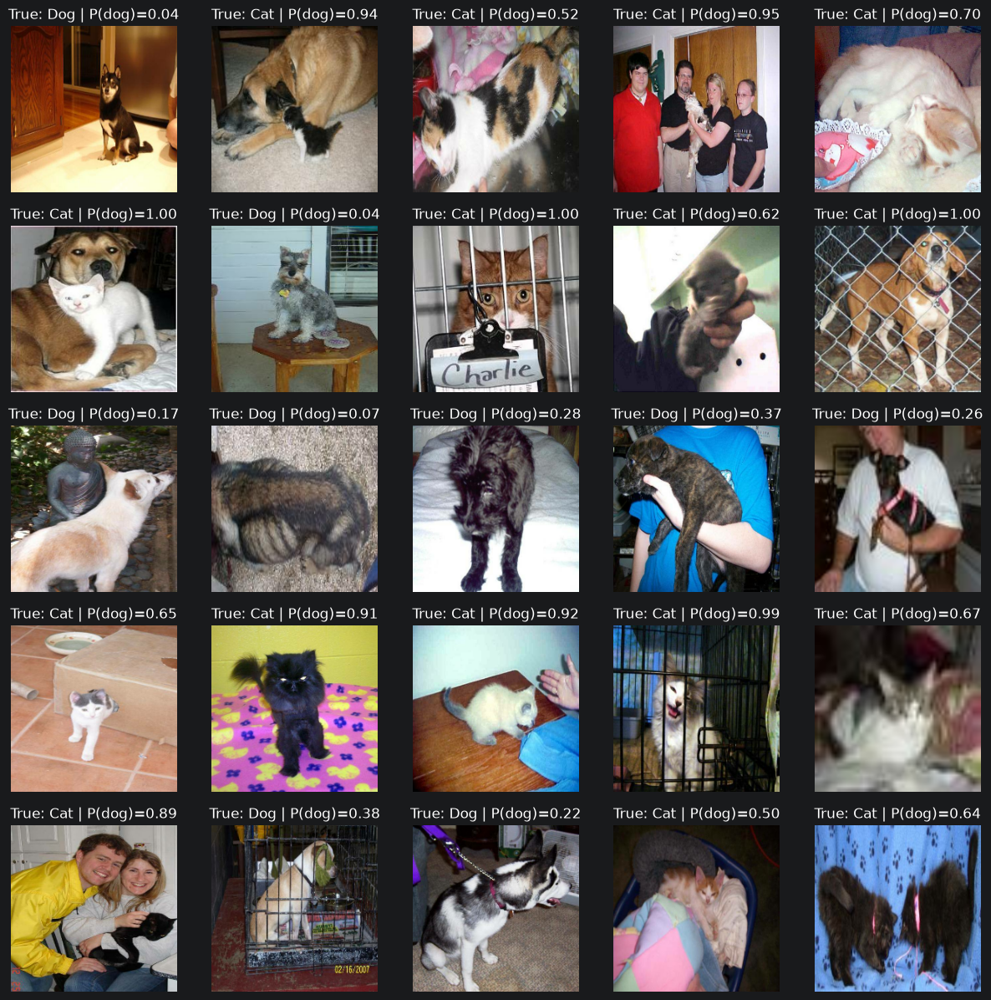

In [26]:
wrong = np.where(val_pred != y_val)[0]
print(f"{len(wrong)} wrong out of {len(y_val)} validation images")

titles = [f"True: {'Dog' if y_val[i] else 'Cat'} | P(dog)={val_probs[i]:.2f}" for i in wrong]
if len(wrong) >= 25:
    show_images(X_val_paths[wrong], titles)
else:
    print("Fewer than 25 mistakes; showing them one by one: ")
    for i, t in zip(wrong, titles):
        plt.imshow(load_image(X_val_paths[i]).numpy().astype('uint8'))
        plt.title(t)
        plt.axis("off")
        plt.show()

# 6. Prepare the submission

🔧 Updated: we predict the whole test set **in batches** with one `predict` call, instead of one image at a time.

391/391 ━━━━━━━━━━━━━━━━━━━━ 712s 2s/step 


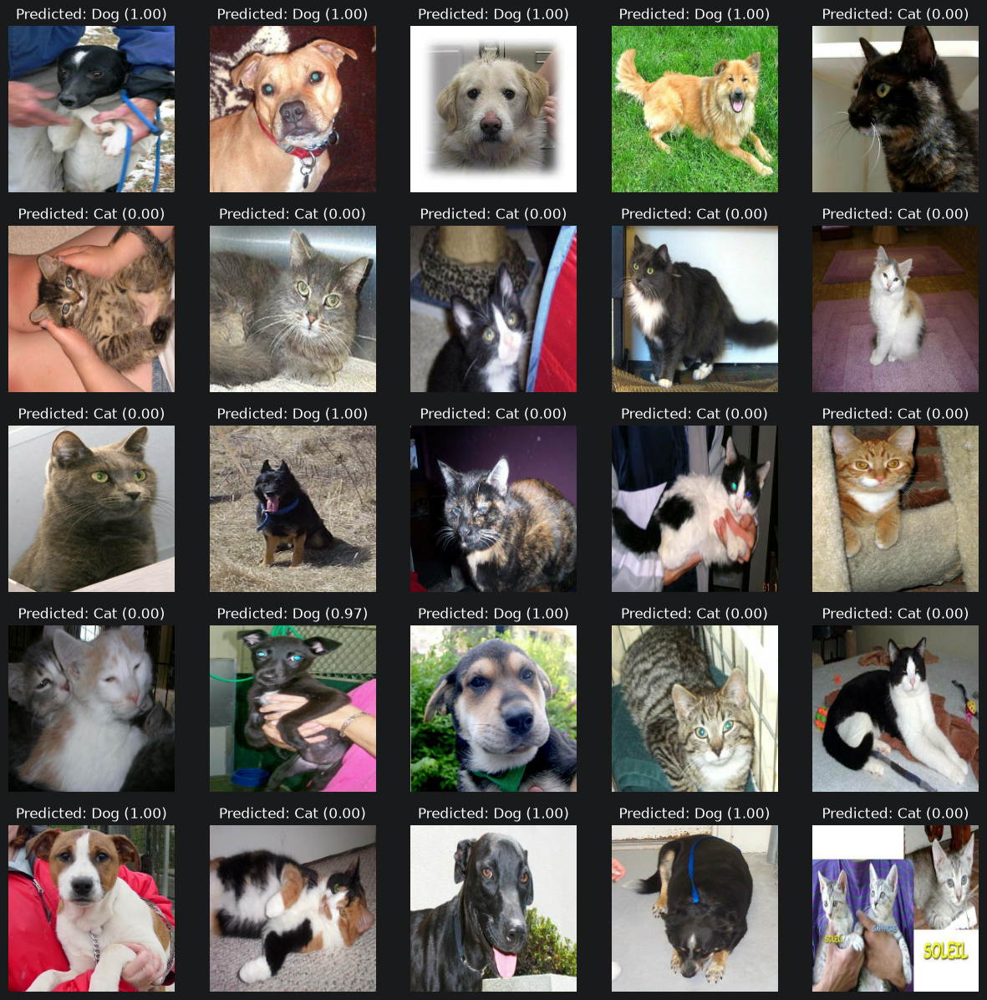

In [27]:
test_probs = model.predict(test_ds).ravel()

show_images(test_paths, [f"Predicted: {'Dog' if p > 0.5 else 'Cat'} ({p:.2f})" for p in test_probs])

### Submission file
🔧 Updated: this competition is scored with **log loss**. A confident wrong answer (for example 0.999 for a cat) gets a huge penalty, so we clip predictions to [0.01, 0.99]. You give up a tiny bit on correct answers to avoid disasters on wrong ones.

In [28]:
submission = pd.DataFrame({"id": test_ids,
                           "label": np.clip(test_probs,0.01, 0.99)})
submission.to_csv(os.path.join(WORK_DIR,"submission.csv"),index=False)
submission.head()

,id,label
0,1,0.99
1,2,0.99
2,3,0.99
3,4,0.99
4,5,0.01


### Save the model
🔧 New: save the trained model so you can load it later without training again: `keras.models.load_model("cats_dogs_resnet50.keras")`.

In [29]:
model.save(os.path.join(WORK_DIR, "cats_dogs_resnet50.keras"))

In [30]:
print(WORK_DIR)

C:\Users\asus\Desktop\Cnn


# 7. Conclusions

A ResNet-50 pretrained on ImageNet, with a small new classifier on top, reaches high validation accuracy on cats vs dogs after only a few epochs, because it reuses visual features it already learned from 1.2 million images.

# 8. Learning wisely: experiments to try

Running the notebook is only the start. You learn by **changing one thing at a time** and predicting the result *before* you run it. Write your guess down, then compare.

1. **Remove `preprocess_input`** (use `load_image` instead of `load_and_preprocess` in `make_dataset`). How much does validation accuracy drop? This shows why preprocessing must match the pretrained model.
2. **Set `base_model.trainable = True` from the start** with Adam at 1e-3, as the original effectively did. Watch the validation loss in the first epochs. What happens to the pretrained features?
3. **Skip phase 2.** Is fine-tuning worth the extra training time on this dataset?
4. **Remove data augmentation and dropout.** Does the gap between training and validation accuracy grow? That gap is overfitting.
5. **Change `SAMPLE_SIZE`** to 1,000, then 5,000. How much data does transfer learning really need? Compare with a small CNN trained from scratch on 1,000 images.
6. **Swap the backbone**: try `EfficientNetB0` or `MobileNetV2` from `tensorflow.keras.applications`. Each has its own `preprocess_input`; use the matching one.
7. **Change the 0.5 threshold** and the clipping values. How do accuracy and log loss each react?

Questions to be able to answer in your own words:
- Why do we freeze the base model first, and why does fine-tuning use a much smaller learning rate?
- What does a skip (residual) connection in ResNet do, and why did it make very deep networks trainable? (See reference 3.)
- `EarlyStopping` uses the validation set to decide when to stop, so the final validation score is slightly optimistic. Why does that make a separate, untouched test set important? (This is why Kaggle scores you on a hidden test set.)

# 9. References
1. Dogs vs. Cats Redux: Kernels Edition — https://www.kaggle.com/c/dogs-vs-cats-redux-kernels-edition
2. Keras guide: Transfer learning & fine-tuning — https://keras.io/guides/transfer_learning/
3. He et al., *Deep Residual Learning for Image Recognition* (the ResNet paper) — https://arxiv.org/abs/1512.03385
4. TensorFlow guide: Better performance with the tf.data API — https://www.tensorflow.org/guide/data_performance